In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('Diabetes-Dataset (1).csv')
# for Patient Id correction
# values are in float converted to int and patient ID is missing was added
df.fillna({'Patient_ID':151}, inplace=True)
df['Patient_ID']=df['Patient_ID'].astype(int)


In [ ]:

df['Age']=df['Age'].replace({
    'thirty': 30
})
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Age'] = df['Age'].astype('Int64')
avg=df['Age'].mean()
print(avg)
df['Age'] = df['Age'].fillna(round(avg))
df['Age']=df['Age'].replace({
    -5: round(avg) ,
    150: round(avg),
})
print(df.to_string())


50.484848484848484
     Patient_ID  Age  Gender      BMI Glucose_mg_dL HbA1c
0             1   59   Other     40.7           171   9.1
1             2   30    Male     26.1            84  10.9
2             3   29  Female     27.8            87   6.2
3             4   25   Other     37.7           101  11.1
4             5   25    Male     31.4           171   4.8
5             6   50  Female     24.2           106   8.3
6             7   41    Male     19.6           216   9.0
7             8   26   Other     31.1           228   5.9
8             9   72  Female     36.4           189   8.6
9            10   56    Male     23.2           116   9.4
10           11   56   Other  unknown           157   9.6
11           12   27    Male     20.0           177   5.7
12           13   80  Female     27.5            89   9.9
13           14   61    Male     34.4           222   8.0
14           15   29    Male     40.6           191   9.4
15           16   57   Other     33.2           184  

In [ ]:
# calculated Average value of BMI to Replace this average vaue with Unrelavent value and blank spaces
row=0
sumbmi=0
bmidf=pd.to_numeric(df['BMI'], errors='coerce')
# print(bmidf)
for j in bmidf :
  if j < 40:
    sumbmi=sumbmi+j
    row=row+1
# print(sumbmi)
# print(row)
avgbmi=sumbmi/row
# print(avgbmi)

df['BMI'] = df['BMI'].fillna(round(avgbmi, 2))

df['BMI']=df['BMI'].replace({
    'unknown': round(avgbmi ,2)
})
df['BMI']=df['BMI'].astype(float)

df.loc[df['BMI'] > 40, 'BMI'] = round(avgbmi, 2)
# print(df.to_string())


df['Gender'].isnull().sum()
# here we checked unrelevent data in gender
df1=df[(df['Gender'] != 'Female') & (df['Gender'] != 'Male')]
# print(df1.to_string())
# calculating the avg BMI of Female and Male
df['Gender']=df['Gender'].replace({
    'Mle':'Male'
})
frow=0
mrow=0
fembmi=0
mbmi=0
# print(df['BMI'].to_string())
for i,k in df[['Gender', 'BMI']].values:
    if i=='Female':
      fembmi=fembmi+ k
      frow=frow+1
    if i=='Male':
       mbmi=mbmi+ k
       mrow=mrow+1

favg=fembmi/frow
print('Female average BMI:',favg)
mavg=mbmi/mrow
print('Male average BMI:',mavg)

row=0

for i,k in df[['Gender','BMI']].values:
  if i=='Other':
    fb= abs(k-round(favg, 2))
    mb=abs(k-round(mavg, 2))
    if fb > mb:
      df.loc[row, 'Gender']='Male'
    else:
      df.loc[row, 'Gender']='Female'
  row=row+1
print(df.to_string())





Female average BMI: 28.256249999999998
Male average BMI: 28.156164383561638
     Patient_ID  Age  Gender   BMI Glucose_mg_dL HbA1c
0             1   59    Male  28.1           171   9.1
1             2   30    Male  26.1            84  10.9
2             3   29  Female  27.8            87   6.2
3             4   25  Female  37.7           101  11.1
4             5   25    Male  31.4           171   4.8
5             6   50  Female  24.2           106   8.3
6             7   41    Male  19.6           216   9.0
7             8   26  Female  31.1           228   5.9
8             9   72  Female  36.4           189   8.6
9            10   56    Male  23.2           116   9.4
10           11   56    Male  28.1           157   9.6
11           12   27    Male  20.0           177   5.7
12           13   80  Female  27.5            89   9.9
13           14   61    Male  34.4           222   8.0
14           15   29    Male  28.1           191   9.4
15           16   57  Female  33.2          

checked BMI irrelavent values and changed

In [ ]:
df['BMI'].isnull().sum()
# print(df['BMI'].dtype)
# checked the BMI patents whose values are less then 5 and greater than 40
df1 = df[(pd.to_numeric(df['BMI'], errors='coerce') < 5) |
         (pd.to_numeric(df['BMI'], errors='coerce') > 40)]
# print(df1.to_string())
# print(len(df1))
# calculated Average vale of BMI to Replace this average vaue with Unrelavent value and blanke
row=0
sumbmi=0
bmidf=pd.to_numeric(df['BMI'], errors='coerce')
# print(bmidf)
for j in bmidf :
  if j < 40:
    sumbmi=sumbmi+j
    row=row+1
print(sumbmi)
print(row)
avgbmi=sumbmi/row
print(avgbmi)

df['BMI'] = df['BMI'].fillna(round(avgbmi, 2))

df['BMI']=df['BMI'].replace({
    'unknown': round(avgbmi ,2)
})

df.loc[df['BMI'] > 40, 'BMI'] = round(avgbmi, 2)

print(df.to_string())



5591.5
199
28.097989949748744
     Patient_ID  Age  Gender   BMI Glucose_mg_dL HbA1c
0             1   59    Male  28.1           171   9.1
1             2   30    Male  26.1            84  10.9
2             3   29  Female  27.8            87   6.2
3             4   25  Female  37.7           101  11.1
4             5   25    Male  31.4           171   4.8
5             6   50  Female  24.2           106   8.3
6             7   41    Male  19.6           216   9.0
7             8   26  Female  31.1           228   5.9
8             9   72  Female  36.4           189   8.6
9            10   56    Male  23.2           116   9.4
10           11   56    Male  28.1           157   9.6
11           12   27    Male  20.0           177   5.7
12           13   80  Female  27.5            89   9.9
13           14   61    Male  34.4           222   8.0
14           15   29    Male  28.1           191   9.4
15           16   57  Female  33.2           184   6.5
16           17   62    Male  17.6 

checking the values of GLucose_mg_dL

In [ ]:
# checked for null values
df['Glucose_mg_dL'].isnull().sum()
# checking data type
df['Glucose_mg_dL'].dtype
# checking the string which is Number name
df2 = df[pd.to_numeric(df['Glucose_mg_dL'], errors='coerce').isna()]
df2
df['Glucose_mg_dL']=df['Glucose_mg_dL'].replace({
    'one hundred': 100})

# df['Glucose_mg_dL']=pd.to_numeric(df['Glucose_mg_dL'], errors='coerce')
df['Glucose_mg_dL']=df['Glucose_mg_dL'].astype(float)
print(df.to_string())


     Patient_ID  Age  Gender   BMI  Glucose_mg_dL HbA1c
0             1   59    Male  28.1          171.0   9.1
1             2   30    Male  26.1           84.0  10.9
2             3   29  Female  27.8           87.0   6.2
3             4   25  Female  37.7          101.0  11.1
4             5   25    Male  31.4          171.0   4.8
5             6   50  Female  24.2          106.0   8.3
6             7   41    Male  19.6          216.0   9.0
7             8   26  Female  31.1          228.0   5.9
8             9   72  Female  36.4          189.0   8.6
9            10   56    Male  23.2          116.0   9.4
10           11   56    Male  28.1          157.0   9.6
11           12   27    Male  20.0          177.0   5.7
12           13   80  Female  27.5           89.0   9.9
13           14   61    Male  34.4          222.0   8.0
14           15   29    Male  28.1          191.0   9.4
15           16   57  Female  33.2          184.0   6.5
16           17   62    Male  17.6          188.

correcting the irrelavent values of Glucose_mg_dL

In [ ]:
df2=df[(df['Glucose_mg_dL']<70) | (df['Glucose_mg_dL']>600)]
print(df2.to_string())

# calculate the average value replace with unreleavent value
row=0
glavg=df['Glucose_mg_dL'].mean()
print(glavg)

df['Glucose_mg_dL']=df['Glucose_mg_dL'].replace({
    -15 : glavg
})
print(df.to_string())


    Patient_ID  Age Gender   BMI  Glucose_mg_dL HbA1c
20          21   71   Male  28.1          -15.0  11.2
149.56
     Patient_ID  Age  Gender   BMI  Glucose_mg_dL HbA1c
0             1   59    Male  28.1         171.00   9.1
1             2   30    Male  26.1          84.00  10.9
2             3   29  Female  27.8          87.00   6.2
3             4   25  Female  37.7         101.00  11.1
4             5   25    Male  31.4         171.00   4.8
5             6   50  Female  24.2         106.00   8.3
6             7   41    Male  19.6         216.00   9.0
7             8   26  Female  31.1         228.00   5.9
8             9   72  Female  36.4         189.00   8.6
9            10   56    Male  23.2         116.00   9.4
10           11   56    Male  28.1         157.00   9.6
11           12   27    Male  20.0         177.00   5.7
12           13   80  Female  27.5          89.00   9.9
13           14   61    Male  34.4         222.00   8.0
14           15   29    Male  28.1         19

checking irrelavent values in HbA1c

In [ ]:
df['HbA1c'].isnull().sum()
df['HbA1c'].dtype
df2 = df[pd.to_numeric(df['HbA1c'], errors='coerce').isna()]
df2

,Patient_ID,Age,Gender,BMI,Glucose_mg_dL,HbA1c
80,81,27,Male,32.6,135.0,NaN
140,141,81,Male,17.9,156.0,six


correcting the  data of HbA1c column

In [ ]:

# replaceing string with numbers
df['HbA1c']=df['HbA1c'].replace({
    'one' : 1,'two' : 2,'three': 3,
    'four':4,'five':5,'six':6,'seven': 7,
    'eight': 8,'nine' :9,'ten': 10,
    'eleven': 11,'twelve': 12
})
#converting data type to float
df['HbA1c']=df['HbA1c'].astype(float)
#calculated avg value
hbavg=df['HbA1c'].mean()
print( hbavg)
#replacing average value with empty cells
df['HbA1c']=df['HbA1c'].fillna(round(hbavg,2))
# print(df.to_string())
df2=df[(df['HbA1c']<3) | (df['HbA1c']>20)]
print(df2.to_string())

df.loc[(df['HbA1c']<3) | (df['HbA1c'] >20),'HbA1c']= round(hbavg,2)
print(df.to_string())



8.049246231155779
    Patient_ID  Age Gender   BMI  Glucose_mg_dL  HbA1c
30          31   79   Male  24.8          106.0   25.0
     Patient_ID  Age  Gender   BMI  Glucose_mg_dL  HbA1c
0             1   59    Male  28.1         171.00   9.10
1             2   30    Male  26.1          84.00  10.90
2             3   29  Female  27.8          87.00   6.20
3             4   25  Female  37.7         101.00  11.10
4             5   25    Male  31.4         171.00   4.80
5             6   50  Female  24.2         106.00   8.30
6             7   41    Male  19.6         216.00   9.00
7             8   26  Female  31.1         228.00   5.90
8             9   72  Female  36.4         189.00   8.60
9            10   56    Male  23.2         116.00   9.40
10           11   56    Male  28.1         157.00   9.60
11           12   27    Male  20.0         177.00   5.70
12           13   80  Female  27.5          89.00   9.90
13           14   61    Male  34.4         222.00   8.00
14           15  

Glucose-HbA1c High-Risk Patients Find patients whose: Glucose is above the dataset average HbA1c is above the dataset average BMI is above the dataset median Return the patients sorted by HbA1c descending

In [ ]:
glavg=df['Glucose_mg_dL'].mean()
hbavg=df['HbA1c'].mean()
bmime=df['BMI'].median()
print(glavg)
print( hbavg)
print(bmime)
df2=df.loc[(df['BMI']>bmime) & (df['Glucose_mg_dL']> glavg) & (df['HbA1c']>hbavg)]
df2.sort_values('HbA1c', ascending= False)

150.38279999999997
7.9645
28.1


,Patient_ID,Age,Gender,BMI,Glucose_mg_dL,HbA1c
44,45,36,Female,32.3,222.0,11.4
77,78,81,Female,30.6,170.0,11.3
121,122,81,Female,30.8,185.0,10.8
115,116,65,Female,36.6,179.0,10.7
19,20,53,Female,39.1,180.0,10.5
192,193,67,Female,32.0,210.0,10.4
158,159,67,Female,36.7,180.0,10.2
40,41,79,Male,39.7,158.0,10.1
91,92,20,Female,37.7,219.0,10.1
165,166,48,Female,35.7,240.0,9.8


Count the number of high-risk patients for each gender.
Create a bar chart showing:
X-axis → Gender
Y-axis → Number of high-risk patients
Create a second line plot showing the average:
Glucose
HbA1c
for each gender.
Add appropriate title, axis labels, and legend.

Gender
Female    15
Male       7
        Glucose_mg_dL     HbA1c
Gender                         
Female     149.086022  7.918280
Male       150.731698  8.027358


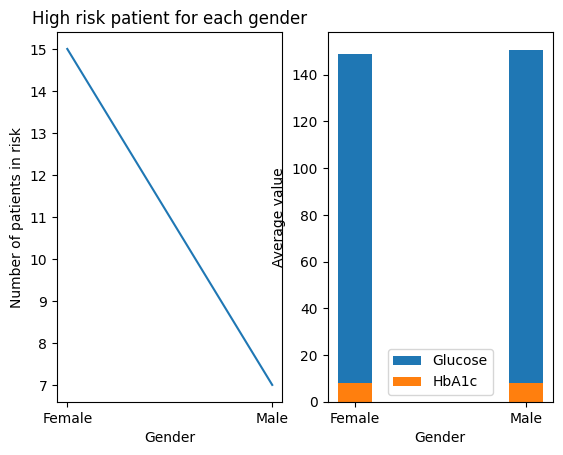

In [ ]:
#calculated how many paient is risk in each gender
df3=df2.groupby('Gender').size()
print(df3.to_string())

x=df3.index
y=df3.values
# ploted a chart
plt.subplot(1,2,1)
plt.plot(x,y,)
plt.title('High risk patient for each gender')
plt.xlabel('Gender')
plt.ylabel('Number of patients in risk')
# plt.show()
# got the average values of glucose and HbA1c of each gender
df4=df.groupby('Gender')[['Glucose_mg_dL','HbA1c']].mean()
print(df4.to_string())

x=df4.index
glucose=df4['Glucose_mg_dL']
hba1c=df4['HbA1c']
plt.subplot(1,2,2)
plt.bar(x, glucose, width=0.2, label='Glucose')
plt.bar(x, hba1c, width=0.2, label='HbA1c')

plt.xlabel('Gender')
plt.ylabel('Average value')
plt.legend()
plt.show()



Age Group Risk Analysis
Create age groups:
Under 30
30–45
46–60
Above 60
For each group, calculate average Glucose, average HbA1c, and average BMI. Identify the group with the highest average values across these measurements.

In [ ]:
df30=df.loc[(df['Age']<30)]

df45=df.loc[(df['Age']>= 30) | (df['Age']<=45)]

df60=df.loc[(df['Age']>=46)| (df['Age']<=60)]

df61=df.loc[(df['Age']>60)]

# calculating the average values


avg30hb1ac=df30['HbA1c'].mean()
avg30glu=df30['Glucose_mg_dL'].mean()
avg30bmi=df30['BMI'].mean()
print('Average below 30 HbA1c:', avg30hb1ac)
print('Average below 30 Glucose:', avg30glu)
print('Average below 30 BMI:', avg30bmi)

avg45hb1ac=df45['HbA1c'].mean()
avg45glu=df45['Glucose_mg_dL'].mean()
avg45bmi=df45['BMI'].mean()
print('Average between 30 and 45 HbA1c:', avg45hb1ac)
print('Average between 30 and 45 Glucose:', avg45glu)
print('Average between 30 and 45 BMI:', avg45bmi)

avg60hb1ac=df60['HbA1c'].mean()
avg60glu=df60['Glucose_mg_dL'].mean()
avg60bmi=df60['BMI'].mean()
print('Average between 46 and 60 HbA1c:', avg60hb1ac)
print('Average between 46 and 60 Glucose:', avg60glu)
print('Average between 46 and 60 BMI:', avg60bmi)

avg61hb1ac=df61['HbA1c'].mean()
avg61glu=df61['Glucose_mg_dL'].mean()
avg61bmi=df61['BMI'].mean()
print('Average above 60 HbA1c:', avg61hb1ac)
print('Average above 60 Glucose:', avg61glu)
print('Average above 60 BMI:', avg60bmi)

#here Iam adding all average value of same group
avg30=avg30hb1ac+avg30bmi+avg30glu

avg45=avg45hb1ac+avg45bmi+avg45glu

avg60=avg60hb1ac+avg60bmi+avg60glu

avg61=avg61hb1ac+avg61bmi+avg61glu

if avg30 >= avg45 and avg30 >= avg60 and avg30 >= avg61:
    print('Below 30 age group patients are in High risk')
elif avg45 >= avg30 and avg45 >= avg60 and avg45 >= avg61:
    print('Between 30 and 45 age group patients are in High risk')
elif avg60 >= avg30 and avg60 >= avg45 and avg60 >= avg61:
    print('Between 45 and 60 age group patients are in High risk')
else:
    print('Above 60 age group patients are in High risk')




Average below 30 HbA1c: 8.108333333333334
Average below 30 Glucose: 155.9047619047619
Average below 30 BMI: 28.630952380952376
Average between 30 and 45 HbA1c: 7.9645
Average between 30 and 45 Glucose: 150.38279999999997
Average between 30 and 45 BMI: 28.1575
Average between 46 and 60 HbA1c: 7.9645
Average between 46 and 60 Glucose: 150.38279999999997
Average between 46 and 60 BMI: 28.1575
Average above 60 HbA1c: 7.847014925373134
Average above 60 Glucose: 149.93373134328357
Average above 60 BMI: 28.1575
Below 30 age group patients are in High risk


Age vs Glucose Investigation
Calculate the average glucose for every age.
Find:
Age with the highest average glucose
Age with the lowest average glucose
Top 5 ages by average glucose
Visualize the relationship using a line plot.

Age
59    320.666667
Name: Glucose_mg_dL, dtype: float64
Age
69    74.5
Name: Glucose_mg_dL, dtype: float64


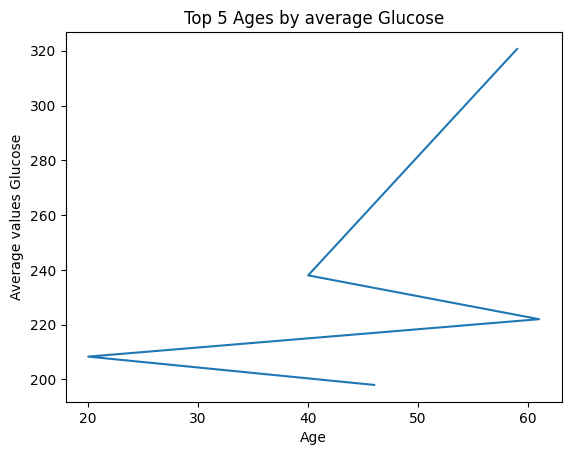

In [ ]:
df3=df.groupby('Age')['Glucose_mg_dL'].mean()
# print(df3.to_string())
h=df3.sort_values(ascending=False).head(1)
print (h)
low=df3.sort_values().head(1)
print(low)
df4= df3.sort_values(ascending=False).head(5)
x=df4.index
y=df4.values
plt.plot(x,y)
plt.title('Top 5 Ages by average Glucose')
plt.xlabel('Age')
plt.ylabel('Average values Glucose')
plt.show()

Multi-Factor Risk Score
Create a Risk_Score:
+1 if Glucose is above the mean
+1 if HbA1c is above the mean
+1 if BMI is above the median
+1 if Age is above the median


In [ ]:
avggl=df['Glucose_mg_dL'].mean()
avgbmi=df['BMI'].median()
avghb=df['HbA1c'].mean()
avga=df['Age'].median()
df['Risk_Score']=0
# print(df.to_string())
row=0
for gl,bm,hb,a,r in df[['Glucose_mg_dL', 'BMI','HbA1c','Age','Risk_Score']].values:
  if gl>avggl:
    r=r+1
  if bm>avgbmi:
    r=r+1
  if hb>avghb:
    r=r+1
  if a>avg:
    r=r+1
  df.loc[row,'Risk_Score']=r
  row=row+1
print(df.to_string())



     Patient_ID  Age  Gender   BMI  Glucose_mg_dL  HbA1c  Risk_Score
0             1   59    Male  28.1         171.00   9.10           3
1             2   30    Male  26.1          84.00  10.90           1
2             3   29  Female  27.8          87.00   6.20           0
3             4   25  Female  37.7         101.00  11.10           2
4             5   25    Male  31.4         171.00   4.80           2
5             6   50  Female  24.2         106.00   8.30           1
6             7   41    Male  19.6         216.00   9.00           2
7             8   26  Female  31.1         228.00   5.90           2
8             9   72  Female  36.4         189.00   8.60           4
9            10   56    Male  23.2         116.00   9.40           2
10           11   56    Male  28.1         157.00   9.60           3
11           12   27    Male  20.0         177.00   5.70           1
12           13   80  Female  27.5          89.00   9.90           2
13           14   61    Male  34.4

Glucose–HbA1c Relationship:
Analyze the relationship between Glucose and HbA1c.
Calculate the correlation.
Create a scatter plot.
Identify patients with high glucose but relatively low HbA1c.
Identify patients with low glucose but relatively high HbA1c.


               Glucose_mg_dL     HbA1c
Glucose_mg_dL       1.000000 -0.018605
HbA1c              -0.018605  1.000000


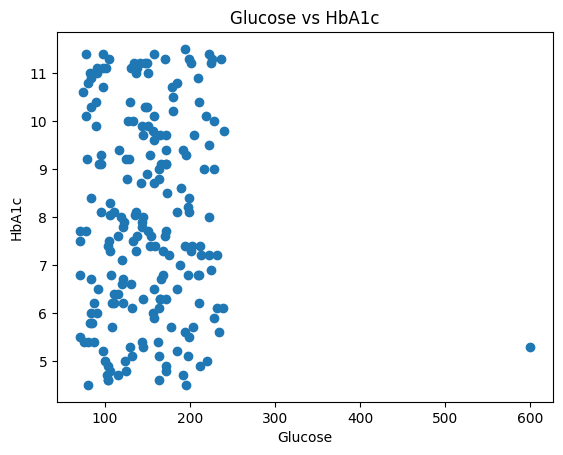

High glucose and low HbA1c
    Patient_ID  Age  Gender   BMI  Glucose_mg_dL  HbA1c  Risk_Score
93          94   66  Female  37.9          212.0    4.9           3
Low glucose and high HbA1c
Empty DataFrame
Columns: [Patient_ID, Age, Gender, BMI, Glucose_mg_dL, HbA1c, Risk_Score]
Index: []


In [ ]:
#calculated corerlation
df2=df[['Glucose_mg_dL','HbA1c']].corr()
# correlation = df['Glucose_mg_dL'].corr(df['BMI'])
print(df2.to_string())
plt.scatter(df['Glucose_mg_dL'], df['HbA1c'])
plt.xlabel('Glucose')
plt.ylabel('HbA1c')
plt.title('Glucose vs HbA1c')
plt.show()
# patients with high glucose but relatively low HbA1c
high_gl_low_hb = df[(df['Glucose_mg_dL'] > 200) &(df['HbA1c'] < 5)]
# patients with low glucose but relatively high HbA1c
low_gl_high_hb = df[(df['Glucose_mg_dL'] < 50) & (df['HbA1c'] > 9)]
print('High glucose and low HbA1c')
print(high_gl_low_hb)
print('Low glucose and high HbA1c')
print(low_gl_high_hb)

Age–BMI Risk Segmentation
Divide patients into 4 groups based on whether their Age and BMI are above or below their respective medians:
Young + Low BMI
Young + High BMI
Older + Low BMI
Older + High BMI
For each group, calculate:
Patient count
Average Glucose
Average HbA1c
Average BMI
Determine which group has the highest average Glucose and HbA1c.

In [ ]:
# Creationg four groups based on Age and BMI
# below 30 are Young age and above 55 are old age
#Young age and low BMI
dfylb = df[(df['Age'] < 30) & (df['BMI'] < 18.5)]
print('Young age and low BMI')
print(dfylb.to_string())
#Young age and High BMI
dfyhb=df[(df['Age']<30) & (df['BMI']>40)]
print('Young age and high BMI')
print(dfyhb.to_string())
#old age and low BMI
dfolb=df[(df['Age']>55) & (df['BMI']<18.5)]
print('old age and low BMI')
print(dfolb.to_string())
#old age and High BMI
dfohb=df[(df['Age']>55) & (df['BMI']>40)]
print('Old age and high BMI')
print(dfohb.to_string())
# Patient count for each group
print('Count of Young age and low BMI:')
print(len(dfylb))
print('Count of Young age and high BMI:')
print(len(dfyhb))
print('Count of old age and low BMI:')
print(len(dfolb))
print('Count of old age and high BMI:')
print(len(dfohb))
# calculating Average Glucose, Average HbA1c, Average BMI  for each group
if len(dfylb)!=0:
  avgylg=dfylb['Glucose_mg_dL'].mean()
  avgylh=dfylb['HbA1c'].mean()
  avgylb=dfylb['BMI'].mean()
else:
  avgylg=0
  avgylh=0
  avgylb=0
print('Average Values of Young age and low BMI has Glucose_mg_dL {}, HbA1c {}, BMI {}'.
format(avgylg, avgylh, avgylb))
if len(dfyhb)!=0:
  avgyhg=dfyhb['Glucose_mg_dL'].mean()
  avgyhh=dfyhb['HbA1c'].mean()
  avgyhb=dfyhb['BMI'].mean()
else:
  avgyhg=0
  avgyhh=0
  avgyhb=0
print('Average Values of Young age and high BMI has Glucose_mg_dL {}, HbA1c {}, BMI {}'.
format(avgyhg, avgyhh, avgyhb))
if len(dfolb)!=0:
  avgolg=dfolb['Glucose_mg_dL'].mean()
  avgolh=dfolb['HbA1c'].mean()
  avgolb=dfolb['BMI'].mean()
else:
  avgolg=0
  avgolh=0
  avgolb=0
print('Average Values of old age and low BMI has Glucose_mg_dL {}, HbA1c {}, BMI {}'.
format(avgolg, avgolh, avgolb))
if len(dfohb)!=0:
  avgohg=dfohb['Glucose_mg_dL'].mean()
  avgohh=dfohb['HbA1c'].mean()
  avgohb=dfohb['BMI'].mean()
else:
  avgohg=0
  avgohh=0
  avgohb=0

print('Average Values of old age and high BMI has Glucose_mg_dL {}, HbA1c {}, BMI {}'.
format(avgohg, avgohh, avgohb))

if avgylg > avgyhg and avgylh > avgyhh and avgylb > avgyhb:
    print('Young age and low BMI average values are high')

elif avgyhg > avgolg and avgyhh > avgolh and avgyhb > avgolb:
    print('Young age and high BMI average values are high')

elif avgolg > avgohg and avgolh > avgohh and avgolb > avgohb:
    print('Old age and low BMI average values are high')

else:
    print('Old age and high BMI average values are high')






Young age and low BMI
     Patient_ID  Age  Gender   BMI  Glucose_mg_dL  HbA1c  Risk_Score
75           76   22    Male  17.4          199.0    8.4           2
157         158   26  Female  17.6          129.0    5.3           0
Young age and high BMI
Empty DataFrame
Columns: [Patient_ID, Age, Gender, BMI, Glucose_mg_dL, HbA1c, Risk_Score]
Index: []
old age and low BMI
     Patient_ID  Age  Gender   BMI  Glucose_mg_dL  HbA1c  Risk_Score
16           17   62    Male  17.6          188.0    7.0           2
138         139   57    Male  18.4          119.0    8.0           2
140         141   81    Male  17.9          156.0    6.0           2
146         147   71    Male  18.3           85.0    5.8           1
154         155   69  Female  18.0           78.0    7.7           1
187         188   58    Male  18.3          232.0    7.2           2
Old age and high BMI
Empty DataFrame
Columns: [Patient_ID, Age, Gender, BMI, Glucose_mg_dL, HbA1c, Risk_Score]
Index: []
Count of Young age and l

Glucose Efficiency Analysis
Create a new column:
Glucose_HbA1c_Ratio = Glucose / HbA1c
Find:
Top 10 patients with the highest ratio
Bottom 10 patients with the lowest ratio
Average ratio by Gender
Average ratio by age group
Visualize the distribution using a histogram.

Top 10 paients with heighest ratio
     Patient_ID  Age  Gender   BMI  Glucose_mg_dL  HbA1c  Risk_Score  Glucose_HbA1c_Ratio
110         111   59  Female  35.8          600.0    5.3           3           113.207547
112         113   67  Female  28.1          220.0    5.0           2            44.000000
129         130   78    Male  28.1          195.0    4.5           2            43.333333
93           94   66  Female  37.9          212.0    4.9           3            43.265306
120         121   68     NaN  20.0          234.0    5.6           2            41.785714
153         154   59    Male  26.1          191.0    4.7           2            40.638298
21           22   40    Male  20.8          238.0    6.1           1            39.016393
7             8   26  Female  31.1          228.0    5.9           2            38.644068
18           19   68  Female  39.9          197.0    5.1           3            38.627451
87           88   20    Male  24.5          231.0    6.1         

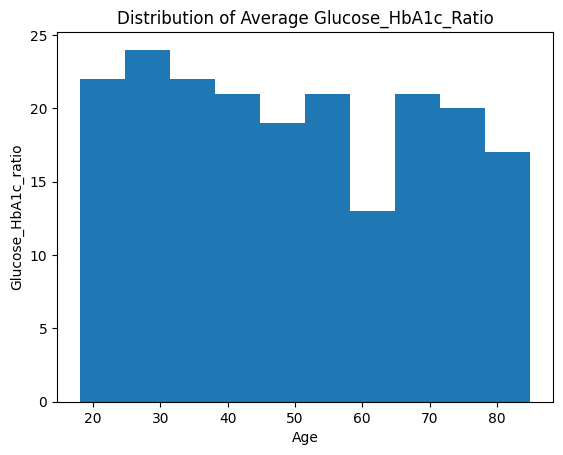

In [ ]:
#create new column for Glucose and HbA1c ratio
df['Glucose_HbA1c_Ratio']=df['Glucose_mg_dL'] / df['HbA1c']
df
df3 =df.sort_values('Glucose_HbA1c_Ratio', ascending=False)
print('Top 10 paients with heighest ratio')
print(df3.head(10).to_string())
print('Bottom 10 paients with heighest ratio')
print(df3.tail(10).to_string())

avgrg=df3.groupby('Gender')['Glucose_HbA1c_Ratio'].mean()
print(avgrg.to_string())

avgra=df3.groupby('Age')['Glucose_HbA1c_Ratio'].mean()
print(avgra.to_string())

x = df['Age']

plt.hist(x)

plt.xlabel('Age')
plt.ylabel('Glucose_HbA1c_ratio')

plt.title('Distribution of Average Glucose_HbA1c_Ratio')

plt.show()
